In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import matplotlib; matplotlib.rcParams.update({'font.size': 18})
import seaborn as sns
pd.set_option('display.max_columns', 12)
import warnings; warnings.filterwarnings("ignore")
import statsmodels.formula.api as smf
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import cross_val_predict, KFold

In [2]:
from pywrangling.jupyter_slides_functions import apply_beamer_theme
from pywrangling.graphing_functions import use_plotplainblind, set_top_ylabel
import course_helpers as chh
apply_beamer_theme(
    "madrid", skip_font_download=True, author="Robert Pettis", date="Fall 2026",
    show_slide_number=True, cell_tags=True,
    notebook_path="18-Double-Debiased-Machine-Learning.ipynb",
)

<IPython.core.display.Javascript object>


✓ Cell tag CSS applied for 34 cell(s):
 cell_index   slide_id                                  tags
         10  slide-0-5 slide_hide_prompt, slide_remove_input
         12  slide-0-6 slide_hide_prompt, slide_remove_input
         20  slide-2-2 slide_hide_prompt, slide_remove_input
         22  slide-2-3 slide_hide_prompt, slide_remove_input
         32  slide-3-6 slide_hide_prompt, slide_remove_input
         36  slide-3-8 slide_hide_prompt, slide_remove_input
         38  slide-3-9 slide_hide_prompt, slide_remove_input
         40 slide-3-10 slide_hide_prompt, slide_remove_input
         42 slide-3-11 slide_hide_prompt, slide_remove_input
         44 slide-3-12 slide_hide_prompt, slide_remove_input
         46 slide-3-13 slide_hide_prompt, slide_remove_input
         49  slide-4-1 slide_hide_prompt, slide_remove_input
         51  slide-4-2 slide_hide_prompt, slide_remove_input
         53  slide-4-3 slide_hide_prompt, slide_remove_input
         55  slide-4-4 slide_hide_prompt, sli

In [3]:
# Presenter clicker remap. Guarded so a student's Restart & Run All
# never breaks on it if pywrangling is missing.
try:
    from pywrangling.jupyter_slides_functions import enable_reveal_key_remap
    enable_reveal_key_remap({
        38: "left",         # Up arrow   -> previous  (clicker left button)
        40: "right",        # Down arrow -> next      (clicker right button)
        27: "up",           # Escape     -> up        (clicker play button)
        66: "down",         # B          -> down      (clicker stop button)
        116: None,          # F5         -> block refresh
        9:  "togglePause",  # Tab        -> black screen
    })
except Exception:
    pass  # not presenting, or pywrangling not installed

In [4]:
def elast(data, y, t):
    return (np.sum((data[t] - data[t].mean()) * (data[y] - data[y].mean())) /
            np.sum((data[t] - data[t].mean()) ** 2))


def cumulative_elast_curve(dataset, prediction, y, t, min_periods=30, steps=100):
    size = dataset.shape[0]
    ordered_df = dataset.sort_values(prediction, ascending=False).reset_index(drop=True)
    n_rows = list(range(min_periods, size, size // steps)) + [size]
    return np.array([elast(ordered_df.head(rows), y, t) for rows in n_rows])


def cumulative_gain_raw(dataset, prediction, y, t, min_periods=30, steps=100):
    size = dataset.shape[0]
    ordered_df = dataset.sort_values(prediction, ascending=False).reset_index(drop=True)
    n_rows = list(range(min_periods, size, size // steps)) + [size]
    return np.array([elast(ordered_df.head(rows), y, t) * (rows / size) for rows in n_rows])


def cumulative_gain(dataset, prediction, y, t, min_periods=30, steps=100):
    # normalized: the baseline (ATE times the share of the sample) is subtracted,
    # so a random ordering sits at zero
    size = dataset.shape[0]
    ordered_df = dataset.sort_values(prediction, ascending=False).reset_index(drop=True)
    n_rows = list(range(min_periods, size, size // steps)) + [size]
    ate = elast(dataset, y, t)
    return np.array([(elast(ordered_df.head(rows), y, t) - ate) * (rows / size) for rows in n_rows])


def gain_plot(curves, title):
    use_plotplainblind()
    fig, ax = plt.subplots(figsize=(10, 5))
    for curve, label in curves:
        pct = np.linspace(0, 100, len(curve))
        ax.plot(pct, curve, lw=2.5, label="%s (AUC %.0f)" % (label, np.nansum(curve)))
    ax.axhline(0, linestyle=":", color="black", lw=1.5, label="Baseline")
    ax.set_xlabel("% of sample, ranked by predicted effect")
    set_top_ylabel(ax, "Normalized cumulative gain")
    ax.set_title(title)
    ax.legend(loc="upper right")
    plt.tight_layout()
    plt.show()


DAYS = {1: "Sunday", 2: "Monday", 3: "Tuesday", 4: "Wednesday",
        5: "Thursday", 6: "Friday", 7: "Saturday"}


def weekday_scatter(data, x, y_, xlabel, ylabel):
    plt.style.use("default")
    matplotlib.rcParams.update({'font.size': 16})
    np.random.seed(123)
    fig, ax = plt.subplots(figsize=(10, 5))
    plot_df = data.sample(1000).assign(weekday=lambda d: d["weekday"].map(DAYS))
    sns.scatterplot(data=plot_df, x=x, y=y_, hue="weekday",
                    hue_order=list(DAYS.values()), palette="viridis", ax=ax)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("")
    set_top_ylabel(ax, ylabel)
    ax.legend(title="weekday", loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=12)
    plt.tight_layout()
    plt.show()

<div class="beamer-meta" data-author="Robert Pettis" data-date="Fall 2026"></div>

# Debiased/Orthogonal Machine Learning

### Causal Machine Learning

<br>

<b style="color:#73000A;">Robert Pettis</b>
Fall 2026

## Before We Start: Updating Your Repo

<span style="display:inline-block; background:#73000A; color:#fff; padding:2px 12px; border-radius:8px; font-weight:700; font-size:.9em;">Reminder</span> &nbsp;same git rhythm as the setup lecture.

| command | what it does |
|---|---|
| `git pull upstream main` | grab today's lecture before class |
| `git checkout -b ps1` | a branch for your own work |
| `git add .` then `git commit -m "..."` | snapshot your changes |
| `git push origin ps1` | send it to your fork, then open a pull request |
| `git status` | what changed, any time |

### Last Time: Meta Learners

- <b style="color:#73000A;">S-learner</b>: a single model with the treatment as a feature
    - Works when the treatment is not a weak predictor; otherwise biased towards zero, or drops the treatment
- <b style="color:#73000A;">T-learner</b>: one model per treatment level
    - Fails when one level has a small sample, forcing heavy regularization
- <b style="color:#73000A;">X-learner</b>: two fitting stages and a propensity score model to correct the model estimated with few data points
- All but the S-learner assume a binary or categorical treatment

### The Paper

- A 2016 paper that sprung a fruitful field: *Double Machine Learning for Treatment and Causal Parameters*
- It took a lot of people to write it
    - Victor Chernozhukov, Denis Chetverikov, Mert Demirer, Esther Duflo, Christian Hansen, Whitney Newey, James Robins
    - Duflo: the 2019 Economics Nobel Prize, with Abhijit Banerjee and Michael Kremer, "for their experimental approach to alleviating global poverty"
- One problem: <b style="color:#73000A;">incredibly difficult to read</b>
- Today: making Debiased/Orthogonal Machine Learning <b style="color:#73000A;">intuitive</b>

### Why Its Own Lecture?

- What caught attention: how <b style="color:#73000A;">well justified</b> Debiased/Orthogonal ML is
- The T, S and X learners all seem a bit <b style="color:#73000A;">hackish</b>
    - An intuitive explanation of why they work, but not very general
- Here, a <b style="color:#73000A;">general framework</b>, both very intuitive and very rigorous
- Works for both <b style="color:#73000A;">continuous and discrete</b> treatments, something neither the T nor the X learner could do
- The papers do an incredible job with the asymptotic analysis of the estimator

### Ice Cream Sales

- The motivating example: an <b style="color:#73000A;">ice cream sales</b> dataset
- Trying to find <b style="color:#73000A;">heterogeneity</b> in the effect of price on sales
- Test set: <b style="color:#73000A;">randomly assigned</b> prices
- Training data: only <b style="color:#73000A;">observational</b> prices, potentially biased

In [5]:
test = pd.read_csv("data/ice_cream_sales_rnd.csv")
train = pd.read_csv("data/ice_cream_sales.csv")
train.head()

,temp,weekday,cost,price,sales
0,17.3,6,1.5,5.6,173
1,25.4,3,0.3,4.9,196
2,23.3,5,1.5,7.6,207
3,26.9,1,0.3,5.3,241
4,20.2,1,1.0,7.2,227


### Prices and Sales, by Weekday

```python
sns.scatterplot(data=train.sample(1000), x="price", y="sales", hue="weekday")
```

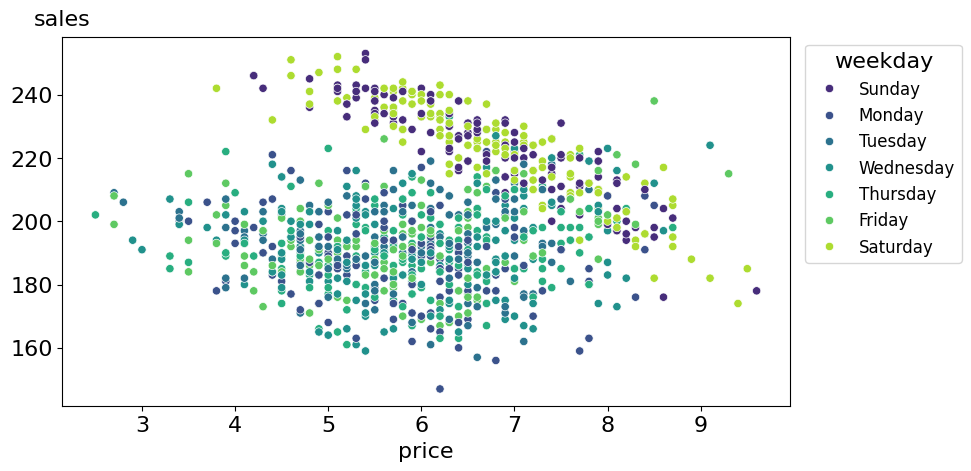

In [6]:
weekday_scatter(train, "price", "sales", "price", "sales")

### One Source of Bias Is Very Clear

- Prices are <b style="color:#73000A;">much higher on the weekend</b> (weekdays 1 and 7)
- Other confounders too: <b style="color:#73000A;">temperature</b> and <b style="color:#73000A;">cost</b>
- Any causal inference with this data has to <b style="color:#73000A;">correct this bias</b>

## ML for Nuisance Parameters

- One way to remove the bias: a <b style="color:#73000A;">linear model</b> for the effect of price on sales, controlling for the confounders

$$
Sales_i = \alpha + \tau\, price_i + \beta_1 temp_i + \beta_2 cost_i + \pmb{\beta_3} Weekday_i + e_i
$$

- $\pmb{\beta_3}$: a vector of parameters, one per weekday dummy
- Only interested in $\tau$, the treatment effect
- The other parameters: <b style="color:#73000A;">nuisance parameters</b>, because we don't care about them
- But we have to <b style="color:#73000A;">get them right</b>, or the treatment effect will be off. Sort of annoying

### Temperature Is Probably Not Linear

- As temperature increases, more people go to the beach and buy ice cream: sales increase
- At some point it is too hot and people stay home: sales <b style="color:#73000A;">drop</b>
- Sales probably <b style="color:#73000A;">peak somewhere</b> and then decrease, so the model above is probably wrong
- It should have been something like

$$
Sales_i = \alpha + \tau\, price_i + \beta_1 temp_i + \beta_2 temp^2_i + \beta_3 cost_i + \pmb{\beta_4} Weekday_i + e_i
$$

<div style="text-align:center;"><img src="images/facure-dml/non-linear.png" width="300"></div>

### Tens or Hundreds of Covariates

- Thinking about how to model nuisance parameters is already <b style="color:#73000A;">boring</b> with a few covariates
- Tens or hundreds of them? With modern datasets, pretty common
- What can we do about it?
- The answer lies in the <b style="color:#73000A;">coolest Econometric theorem ever derived</b>

## Frisch-Waugh-Lovell

- 20th century econometricians who noticed the coolest thing about linear regression
- Not new: regression residuals, fixed effects. But key to Orthogonal-ML, so worth recapping
- A linear model with a set of features $X_1$ and another set $X_2$

$$
\hat{Y} = \hat{\beta_1} X_1 + \hat{\beta_2} X_2
$$

- $X_1$, $X_2$: feature matrices, one column per feature, one row per observation
- The same $\hat{\beta_1}$ comes out of four steps

### The Four Steps

1. Regress the outcome $y$ on the second set of features: $\hat{y^*} = \hat{\gamma_1} X_2$
2. Regress the first set of features on the second: $\hat{X_1} = \hat{\gamma_2} X_2$
3. Obtain the residuals $\tilde{X}_1 = X_1 - \hat{X_1}$ and $\tilde{y} = y - \hat{y^*}$
4. Regress the residuals of the outcome on the residuals of the features: $\tilde{y} = \hat{\beta_1} \tilde{X}_1$

- <b style="color:#73000A;">Insanely cool</b>: one set of features can be just the treatment variable
- So all the nuisance parameters can be estimated <b style="color:#73000A;">separately</b>
    - Regress the outcome on the features: outcome residuals
    - Regress the treatment on the features: treatment residuals
    - Regress the outcome residuals on the treatment residuals
- The same estimate as regressing the outcome on features and treatment at the same time

### Don't Take My Word for It

- Something everyone interested in causal inference should do <b style="color:#73000A;">at least once</b>
- First, the effects of the covariates on the outcome (sales) and on the treatment (price)

```python
my = smf.ols("sales ~ temp + C(weekday) + cost", data=train).fit()
mt = smf.ols("price ~ temp + C(weekday) + cost", data=train).fit()
```

- Then, with the residuals, the ATE of price on sales

```python
smf.ols("sales_res ~ price_res",
        data=train.assign(sales_res=my.resid,    # sales residuals
                          price_res=mt.resid)    # price residuals
        ).fit().summary().tables[1]
```

In [7]:
my = smf.ols("sales ~ temp + C(weekday) + cost", data=train).fit()
mt = smf.ols("price ~ temp + C(weekday) + cost", data=train).fit()

smf.ols("sales_res ~ price_res",
        data=train.assign(sales_res=my.resid,    # sales residuals
                          price_res=mt.resid)    # price residuals
        ).fit().summary().tables[1]

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,-3.703e-13,0.111,-3.35e-12,1.000,-0.217,0.217
price_res,-4.0004,0.110,-36.428,0.000,-4.216,-3.785


### All at Once

- ATE estimated at <b style="color:#73000A;">-4</b>: each unit increase in price lowers sales by 4 units
- Now the same parameter, with the treatment and the covariates in the same model

```python
float(smf.ols("sales ~ price + temp + C(weekday) + cost", data=train).fit().params["price"])
```

In [8]:
float(smf.ols("sales ~ price + temp + C(weekday) + cost", data=train).fit().params["price"])

-4.000429145475387

### Regression on Residuals

- The <b style="color:#73000A;">same number</b>: all at once, or in the FWL steps, is mathematically the same
- The treatment effect comes from <b style="color:#73000A;">regression on residuals</b>
    - Residuals from regressing $Y$ on $X$, regressed on the residuals from regressing $T$ on $X$
- With $\sim$ as the regression operator, FWL in one line

$$
(Y - (Y \sim X)) \sim (T - (T \sim X))
$$

- Which estimates $\tau$ in

$$
Y_i - E[Y_i \mid X_i] = \tau \cdot (T_i - E[T_i \mid X_i]) + \epsilon
$$

### What Can We Do With This?

- Separates the estimation of the <b style="color:#73000A;">causal parameter</b> from that of the <b style="color:#73000A;">nuisance parameters</b>
- Still unanswered: how to avoid the hassle of specifying the correct functional form for the nuisance parameters?
- How to focus only on the causal parameter without worrying about the nuisance parameters?
- Here is where <b style="color:#73000A;">machine learning</b> comes to play

<div style="text-align:center;"><img src="images/facure-dml/drown-ols.png" width="260"></div>

## Frisch-Waugh-Lovell on Steroids

- Double/Debiased ML: the FWL theorem <b style="color:#73000A;">on steroids</b>
- The propensity score lecture already swapped out one piece of FWL: the regression of $T$ on $X$ became a <b style="color:#73000A;">logit</b>
- We simply do it again... now in <b style="color:#73000A;">both slots</b>: any ML model that predicts well can build the outcome residual and the treatment residual

$$
\underbrace{Y_i - \hat{M}_y(X_i)}_{\tilde{Y}_i} = \tau \cdot \underbrace{(T_i - \hat{M}_t(X_i))}_{\tilde{T}_i} + \epsilon_i
$$


- $\hat{M}_y(X_i)$ estimates $E[Y \mid X]$, $\hat{M}_t(X_i)$ estimates $E[T \mid X]$
- A flexible ML model picks up the <b style="color:#73000A;">interactions and non linearities</b> on its own, reducing assumptions we need to make
- The causal estimate still comes from the last step, a regression of residual on residual: the <b style="color:#73000A;">familiar OLS form and interpretation</b>

### The Orthogonalisation Procedure with Machine Learning Involved...

- Provided there are <b style="color:#73000A;">no unobserved confounders</b>, the ATE comes from

1. Estimate the outcome $Y$ with features $X$ using a flexible ML regression model $M_y$
2. Estimate the treatment $T$ with features $X$ using a flexible ML regression model $M_t$
3. Obtain the residuals $\tilde{Y} = Y - M_y(X)$ and $\tilde{T} = T - M_t(X)$
4. Regress the residuals of the outcome on the residuals of the treatment: $\tilde{Y} = \alpha + \tau \tilde{T}$

- $\tau$ is the ATE, estimated for example with OLS

### The Price of Flexibility

- The power you gain with ML is <b style="color:#73000A;">flexibility</b>: it captures complicated functional forms in the nuisance relationships
- That flexibility is also troublesome: now we have to take <b style="color:#73000A;">overfitting</b> into account

<div style="text-align:center;"><img src="images/facure-dml/ml-problem.png" width="520"></div>

- Chernozhukov et al (2016) has a much more in depth and rigorous explanation; here, intuition

### If $M_y$ Overfits

- The residual $\tilde{Y}$ will be <b style="color:#73000A;">smaller than it should be</b>
- But $M_y$ never sees $T$. How can it steal the $T$ to $Y$ relationship?
- Each $Y_i$ contains $\tau \tilde{T}_i$, the effect of that day's price surprise. From the covariates' point of view that is <b style="color:#73000A;">noise</b>: nothing in $X$ predicts it
- A well behaved $M_y$ leaves the noise alone. It lands in $\tilde{Y}_i$, where the final regression can find it
- An overfit $M_y$ <b style="color:#73000A;">memorizes</b> the individual $Y_i$, noise and all. Part of $\tau \tilde{T}_i$ gets swallowed into the prediction and disappears from the residual
- Extreme case: a model that fits every point perfectly gives $\tilde{Y}_i = 0$ for everyone, and the residual regression returns $\tau = 0$
- So the residual regression is <b style="color:#73000A;">biased towards zero</b>: $M_y$ ate part of the causal relationship instead of leaving it to the last step

### If $M_t$ Overfits

- It explains <b style="color:#73000A;">more of the variance in $T$</b> than it should
- The treatment residual has less variance than it should
- Less variance in the treatment: the <b style="color:#73000A;">variance of the final estimator will be high</b>
- As if the treatment is the same for almost everyone
    - Very difficult to estimate what would happen under different treatment levels
- Side note: this also happens when $T$ is a deterministic function of $X$, meaning <b style="color:#73000A;">positivity is violated</b>
    - REVIEW: when a specific subgroup of individuals (defined by their covariates) has a zero (or near-zero) probability of receiving treatment, T

### So what do we do about it? 

Solution: k-Fold Cross Validation and Out-of-Fold Residuals

<div style="text-align:center;"><img src="images/facure-dml/cross-prediction.png" width="620"></div>

- Split the data into <b style="color:#73000A;">K parts</b> of equal size (usually 10)
- For each part $k$, estimate the ML models on the other $K-1$ parts and make the residuals on part $k$
- <b style="color:#73000A;">Out-of-fold</b> prediction: fit the model on one part, predict and make residuals on another
- Even if the model overfits, it won't drive the residuals to zero artificially
- Combine the K parts: Each row gets one out-of-fold prediction, from the model that used it as it's testing data
- Stack the K parts back into a single full length column of residuals, one row per observation 
- Then <b style="color:#73000A;">one</b> regression on all the rows: $\tilde{Y} = \alpha + \tau \tilde{T}$
    - The paper also allows for alternatives

### Our Example: the Treatment Model $M_t$

- A step by step implementation, explaining what each step does
- Boosted trees predict prices from `temp`, `weekday` and `cost`
- Cross predictions, from `sklearn`'s `cross_val_predict`
- The average $\hat{\mu_t}$ is added to the residuals just for visualization

```python
y = "sales"
T = "price"
X = ["temp", "weekday", "cost"]

debias_m = HistGradientBoostingRegressor(max_depth=3, early_stopping=False,
                                         random_state=0)

train_pred = train.assign(price_res=train[T] -
                          cross_val_predict(debias_m, train[X], train[T], cv=5)
                          + train[T].mean())    # add mu_t for visualization
```

In [9]:
y = "sales"
T = "price"
X = ["temp", "weekday", "cost"]

debias_m = HistGradientBoostingRegressor(max_depth=3, early_stopping=False,
                                         random_state=0)

train_pred = train.assign(price_res=train[T] -
                          cross_val_predict(debias_m, train[X], train[T], cv=5)
                          + train[T].mean())    # add mu_t for visualization

In [10]:
# Shorthand used by the compact versions below (skip cells, not in the slideshow)
def boost(**kw):
    return HistGradientBoostingRegressor(max_depth=3, early_stopping=False, random_state=0, **kw)

### The Debias Model

- $M_t$ is the <b style="color:#73000A;">debias model</b>: its role in Double/Debiased ML is debiasing the treatment
- The residuals $\tilde{T} = T - M_t(X)$: a version of the treatment where all the <b style="color:#73000A;">confounding bias from $X$ has been removed</b>
- $\tilde{T}$ is <b style="color:#73000A;">orthogonal</b> to $X$
   - $\tilde{T}$ can no longer be explained by $X$, because it already was

### The Weekend Bias Is Gone

- The same plot as before, price replaced by the <b style="color:#73000A;">price residuals</b>
- Before, weekends had higher prices. Now all the weekdays have the same price residual distribution

```python
sns.scatterplot(data=train_pred.sample(1000), x="price_res", y="sales", hue="weekday")
```

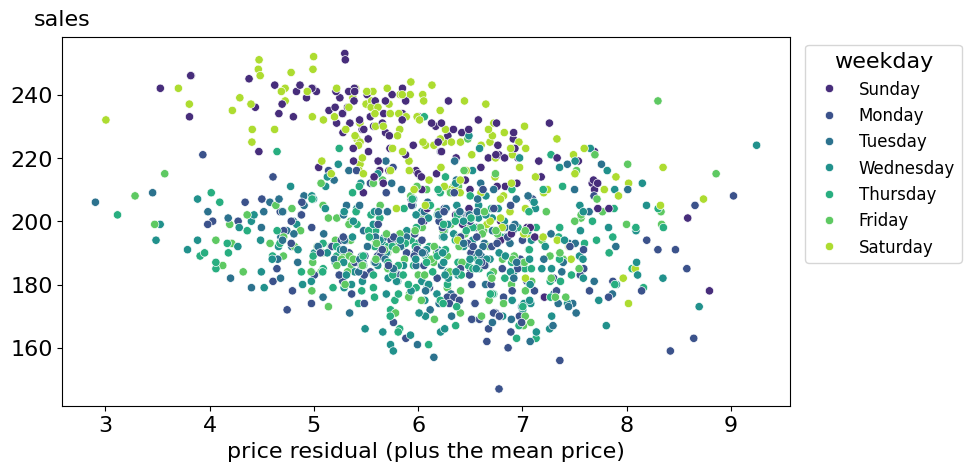

In [11]:
weekday_scatter(train_pred, "price_res", "sales", "price residual (plus the mean price)", "sales")

### The Denoise Model $M_y$

- $M_t$ debiases the treatment. $M_y$ <b style="color:#73000A;">removes the variance from $Y$</b>: the denoising model
- $M_y$ creates a version of the outcome where all the variance due to $X$ has been explained away
- Easier causal estimation in $\tilde{Y}$: less noise, the causal relationship is easier to see

```python
denoise_m = HistGradientBoostingRegressor(max_depth=3, early_stopping=False,
                                          random_state=0)

train_pred = train_pred.assign(sales_res=train[y] -
                               cross_val_predict(denoise_m, train[X], train[y], cv=5)
                               + train[y].mean())
```

In [12]:
denoise_m = HistGradientBoostingRegressor(max_depth=3, early_stopping=False,
                                          random_state=0)

train_pred = train_pred.assign(sales_res=train[y] -
                               cross_val_predict(denoise_m, train[X], train[y], cv=5)
                               + train[y].mean())

### The Variance in $Y$ Is Much Smaller

- The same graph, sales replaced by the <b style="color:#73000A;">sales residual</b>
- Now it is easy to see the <b style="color:#73000A;">negative</b> relationship between prices and sales

```python
sns.scatterplot(data=train_pred.sample(1000), x="price_res", y="sales_res", hue="weekday")
```

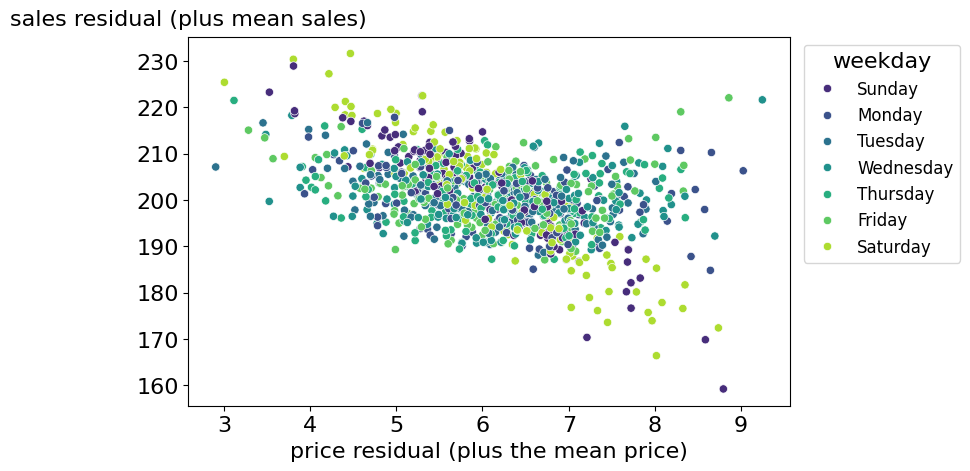

In [13]:
weekday_scatter(train_pred, "price_res", "sales_res",
                "price residual (plus the mean price)", "sales residual (plus mean sales)")

### Regression on the Residuals

```python
final_model = smf.ols(formula="sales_res ~ price_res", data=train_pred).fit()
final_model.summary().tables[1]
```

In [14]:
final_model = smf.ols(formula="sales_res ~ price_res", data=train_pred).fit()
final_model.summary().tables[1]

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,224.5469,0.443,506.490,0.000,223.678,225.416
price_res,-3.9210,0.071,-54.939,0.000,-4.061,-3.781


In [15]:
# Compact version of the ATE cells above, same result
price_res = train[T] - cross_val_predict(boost(), train[X], train[T], cv=5)
sales_res = train[y] - cross_val_predict(boost(), train[X], train[y], cv=5)
compact_ate = smf.ols("sales_res ~ price_res",
                      data=train.assign(sales_res=sales_res, price_res=price_res)).fit().params

In [16]:
from IPython.display import HTML
HTML(chh.ice_cream_animation(train_pred).to_html5_video())

### Residualized Against Raw

- With the residualized, or orthogonalised, sales and price: very confident the relationship is <b style="color:#73000A;">negative</b>
    - Makes a lot of sense. As we increase prices, demand for ice cream should fall
- The un-residualized, raw relationship: because of bias, <b style="color:#73000A;">positive</b>
    - In anticipation of high sales, prices are increased

```python
smf.ols(formula="sales ~ price", data=train_pred).fit().summary().tables[1]
```

In [17]:
smf.ols(formula="sales ~ price", data=train_pred).fit().summary().tables[1]

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,192.9679,1.013,190.414,0.000,190.981,194.954
price,1.2294,0.162,7.575,0.000,0.911,1.547


## Linear CATE Estimation with Double-ML

- So far, the Average Treatment Effect. Double/Debiased ML can also estimate <b style="color:#73000A;">treatment effect heterogeneity</b>, the CATE
- The causal parameter $\tau$ changes with the unit's covariates

$$
Y_i - M_y(X_i) = \tau(X_i) \cdot (T_i - M_t(X_i)) + \epsilon_i
$$

- Same residualised price and sales, now the price residuals <b style="color:#73000A;">interacted with the other covariates</b>: a linear CATE model

$$
\tilde{Y_i} = \alpha + \beta_1 \tilde{T_i} + \pmb{\beta}_2 \pmb{X_i} \tilde{T_i} + \epsilon_i
$$

- CATE predictions on the randomised test set. The final model is linear, so the CATE is mechanical

$$
\hat{\mu}(\partial Sales_i, X_i) = M(Price=1, X_i) - M(Price=0, X_i)
$$

### The Linear CATE Model in Code

```python
final_model_cate = smf.ols(formula="sales_res ~ price_res * (temp + C(weekday) + cost)",
                           data=train_pred).fit()

cate_test = test.assign(cate=final_model_cate.predict(test.assign(price_res=1))
                        - final_model_cate.predict(test.assign(price_res=0)))
```

- How good is it at separating high price sensitivity from low? The <b style="color:#73000A;">cumulative elasticity curve</b>

In [18]:
final_model_cate = smf.ols(formula="sales_res ~ price_res * (temp + C(weekday) + cost)",
                           data=train_pred).fit()

cate_test = test.assign(cate=final_model_cate.predict(test.assign(price_res=1))
                        - final_model_cate.predict(test.assign(price_res=0)))

cate_test[["temp", "weekday", "cost", "price", "sales", "cate"]].head()

,temp,weekday,cost,price,sales,cate
0,25.8,1,0.3,7,230,-11.218539
1,22.7,3,0.5,4,190,-1.653659
2,33.7,7,1.0,5,237,-10.037207
3,23.0,4,0.5,5,193,-1.743480
4,24.4,1,1.0,3,252,-10.487555


### The Cumulative Elasticity Curve

- Sort the test set by the predicted effect, <b style="color:#73000A;">largest first</b>: the days where a price rise should hurt sales the least
- Walk down the ranking. At each cut, the <b style="color:#73000A;">elasticity of the top group</b>: the slope of sales on price within those days
- Prices are random in the test set, so that slope is a real effect. The model only chose the order
- A good ranking starts well above the ATE and falls towards it. At 100% it is the ATE, whatever the model said
- Here the top days even have a <b style="color:#73000A;">positive</b> slope: on those days a higher price came with more sales

```python
elast_curve_test = cumulative_elast_curve(cate_test, "cate", y=y, t=T)
```

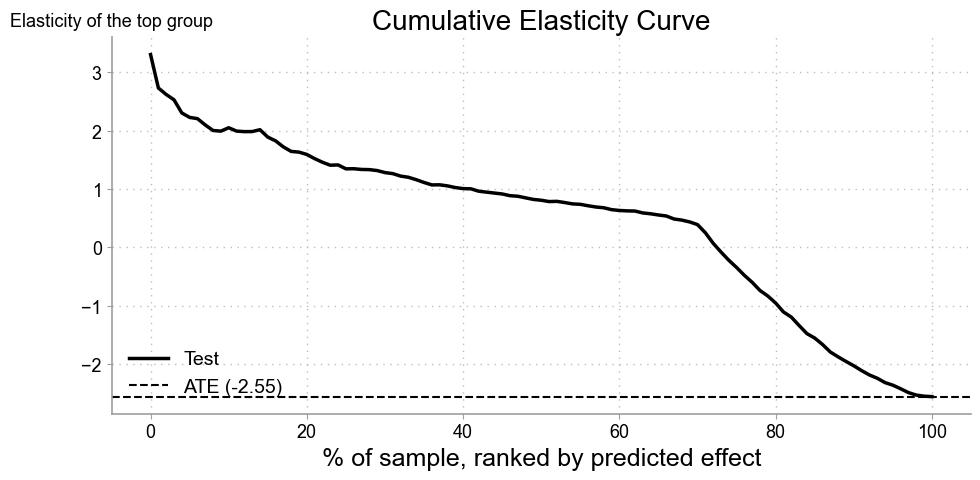

In [19]:
elast_curve_test = cumulative_elast_curve(cate_test, "cate", y=y, t=T)
ate_test = elast(test, y, T)

use_plotplainblind()
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(np.linspace(0, 100, len(elast_curve_test)), elast_curve_test, lw=2.5, label="Test")
ax.axhline(ate_test, linestyle="--", color="black", lw=1.5, label="ATE (%.2f)" % ate_test)
ax.set_xlabel("% of sample, ranked by predicted effect")
set_top_ylabel(ax, "Elasticity of the top group")
ax.set_title("Cumulative Elasticity Curve")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

### The Cumulative Gain Curve

- The elasticity curve is noisy at the start: the first point is a slope fit on 30 days
- Multiply each point by the <b style="color:#73000A;">share of the sample</b> it uses, elasticity times $k/n$
- Early points shrink towards zero, the last point is pinned at the ATE: anchored at both ends
- A random ordering has the ATE at every cut, times $k/n$: a <b style="color:#73000A;">straight line</b> from zero to the ATE
- A good model runs <b style="color:#73000A;">above</b> that line: its top group has an effect above the average

```python
gain_raw_test = cumulative_gain_raw(cate_test, "cate", y=y, t=T)
```

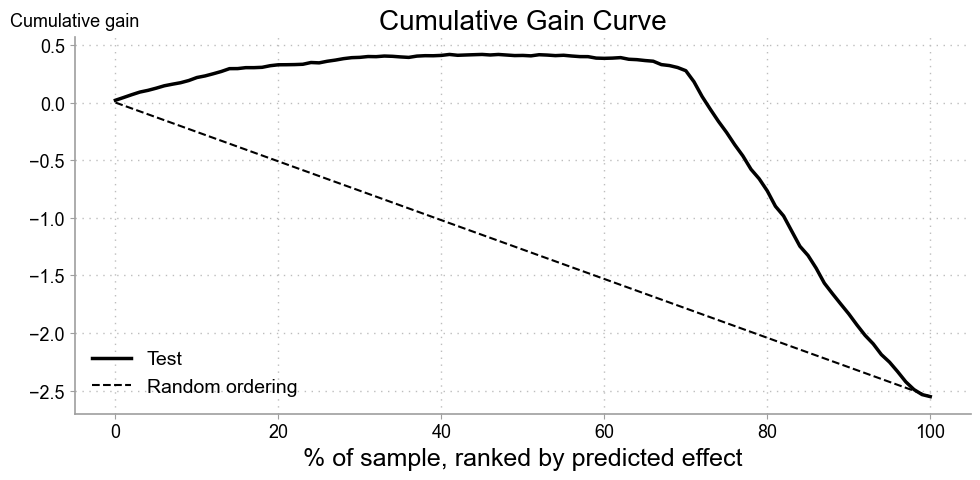

In [20]:
gain_raw_test = cumulative_gain_raw(cate_test, "cate", y=y, t=T)

use_plotplainblind()
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(np.linspace(0, 100, len(gain_raw_test)), gain_raw_test, lw=2.5, label="Test")
ax.plot([0, 100], [0, ate_test], linestyle="--", color="black", lw=1.5, label="Random ordering")
ax.set_xlabel("% of sample, ranked by predicted effect")
set_top_ylabel(ax, "Cumulative gain")
ax.set_title("Cumulative Gain Curve")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

### The Normalized Cumulative Gain Curve

- Subtract the random line from the curve: the baseline is now <b style="color:#73000A;">flat at zero</b>
- A good model is a hump above zero, a backwards ranking a dip below, random is zero, whatever the sign of the ATE
- The <b style="color:#73000A;">AUC</b>, the area under the hump, is the one number to compare models with
- `cumulative_gain` here does that subtraction, the convention since lecture 16

```python
gain_curve_test = cumulative_gain(cate_test, "cate", y=y, t=T)
gain_plot([(gain_curve_test, "Test")], "Normalized Cumulative Gain Curve")
```

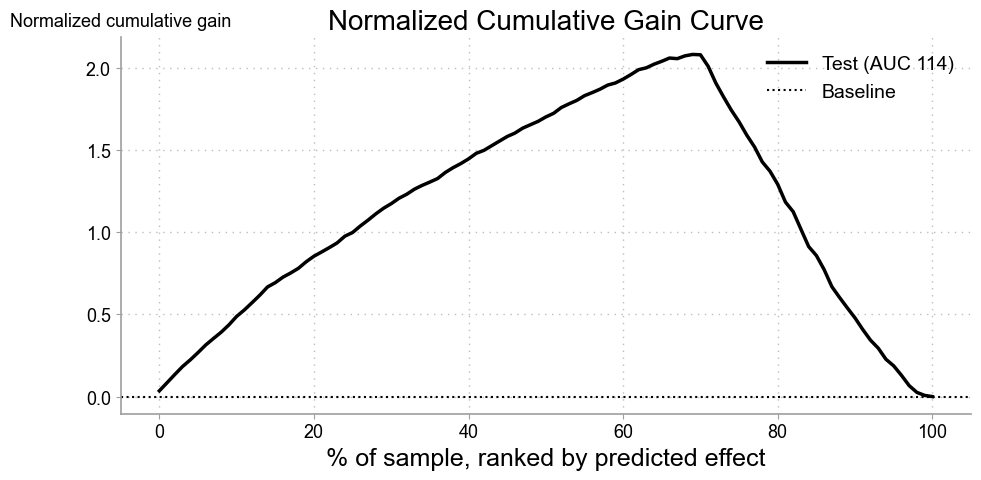

In [21]:
gain_curve_test = cumulative_gain(cate_test, "cate", y=y, t=T)
gain_plot([(gain_curve_test, "Test")], "Normalized Cumulative Gain Curve")

### The R-Learner

- Double/Debiased ML with a final linear model is <b style="color:#73000A;">already very good</b>. Maybe we can do even better
- A very general procedure, understood just like a meta-learner
- Nie and Wager called it the <b style="color:#73000A;">R-Learner</b>: for Robinson (1988), and to emphasize the role of residualization
- The procedure defines a <b style="color:#73000A;">new loss function</b> that we can minimize however we want

## Non Parametric Double/Debiased ML

- Double-ML frees us from learning the nuisance parameters; all attention on the causal parameter, ATE or CATE
- But the final causal model was still <b style="color:#73000A;">linear</b>: price impacts sales linearly
- Probably OK for a small range of prices. Microeconomic theory says not necessarily
    - At low prices, a unit increase lowers demand by 2 units; at higher prices, by just 1 unit
- We could speculate about the functional form, or <b style="color:#73000A;">delegate it to a ML model</b>
- Possible with a few changes to the algorithm. First, orthogonalize as before

```python
train_pred = train.assign(
    price_res=train[T] - cross_val_predict(debias_m, train[X], train[T], cv=5),
    sales_res=train[y] - cross_val_predict(denoise_m, train[X], train[y], cv=5))
```

In [22]:
train_pred = train.assign(
    price_res=train[T] - cross_val_predict(debias_m, train[X], train[T], cv=5),
    sales_res=train[y] - cross_val_predict(denoise_m, train[X], train[y], cv=5))

### A Causal Loss Function

- Double/Debiased-ML models the data as

$$
Y_i = \hat{M}_y(X_i) + \tau(X_i) \big(T_i - \hat{M}_t(X)\big) + \hat{\epsilon}_i
$$

- Rearrange to isolate the error term

$$
\hat{\epsilon}_i = \big(Y_i - \hat{M}_y(X_i)\big) - \tau(X_i) \big(T_i - \hat{M}_t(X)\big)
$$

- Nothing short of awesome: a <b style="color:#73000A;">causal loss function</b>. Minimize its square and we estimate $\tau(X_i)$, the CATE

$$
\hat{L}_n(\tau(x)) = \frac{1}{n} \sum^n_{i=1}\bigg(\big(Y_i - \hat{M}_y(X_i)\big) - \tau(X_i) \big(T_i - \hat{M}_t(X)\big)\bigg)^2
$$

- Also called the <b style="color:#73000A;">R-Loss</b>, since it is what the R-learner minimizes

### The Weight Trick

- Decluttered, with the residualized treatment and outcome

$$
\hat{L}_n(\tau(x)) = \frac{1}{n} \sum^n_{i=1}\bigg( \tilde{Y}_i - \tau(X_i) \tilde{T}_i \bigg)^2
$$

- Some algebraic parkour: take $\tilde{T}_i$ out of the term:




$$
\hat{L}_n(\tau(x)) = \frac{1}{n} \sum^n_{i=1}\bigg(\tilde{T}_i \left( \frac{\tilde{Y}_i}{\tilde{T}_i} - \tau(X_i) \right)\bigg)^2
$$

And now take it out of the parentheses:
$$
\hat{L}_n(\tau(x)) = \frac{1}{n} \sum^n_{i=1} \tilde{T}_i^2 \left(\frac{\tilde{Y}_i}{\tilde{T}_i} - \tau(X_i)\right)^2
$$


So we are minimizing the term in parentheses weighted y T-tilde squared

### Three Steps, Then the Code

- With the nuisance models and the residualised treatment and outcome in hand

1. Create weights $\tilde{T}_i^2$
2. Create our target $\tilde{Y}_i / \tilde{T}_i$
3. Use <b style="color:#73000A;">any prediction method</b> to predict the target (2) with the weights (1)

```python
model_final = HistGradientBoostingRegressor(max_depth=3, early_stopping=False,
                                            random_state=0)

w = train_pred["price_res"] ** 2                         # the weights
y_star = train_pred["sales_res"] / train_pred["price_res"]   # the transformed target

model_final.fit(X=train[X], y=y_star, sample_weight=w)   # weighted regression

cate_test_non_param = test.assign(cate=model_final.predict(test[X]))
```

- An off-the-shelf predictive model, estimating the CATE. Any predictive model can be the final model now

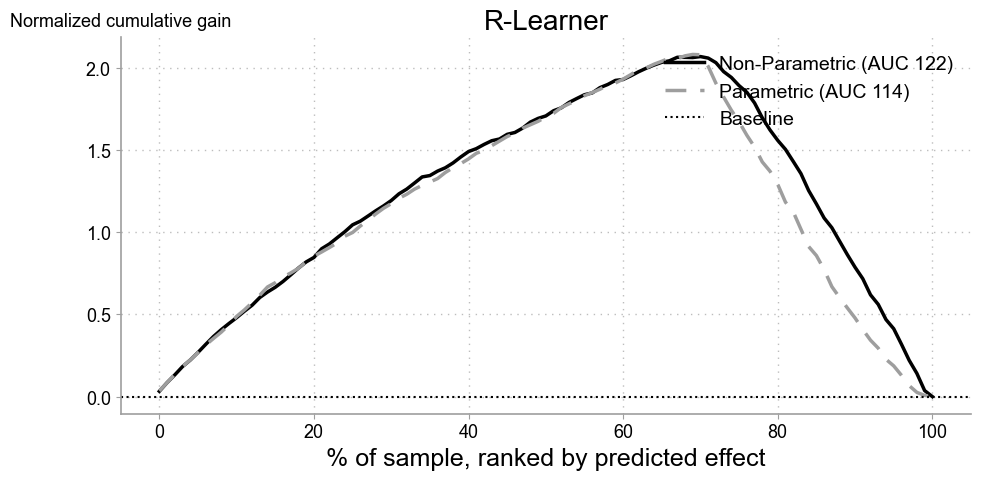

In [23]:
model_final = HistGradientBoostingRegressor(max_depth=3, early_stopping=False,
                                            random_state=0)

w = train_pred["price_res"] ** 2                         # the weights
y_star = train_pred["sales_res"] / train_pred["price_res"]   # the transformed target

model_final.fit(X=train[X], y=y_star, sample_weight=w)   # weighted regression

cate_test_non_param = test.assign(cate=model_final.predict(test[X]))

gain_curve_test_non_param = cumulative_gain(cate_test_non_param, "cate", y=y, t=T)
gain_plot([(gain_curve_test_non_param, "Non-Parametric"), (gain_curve_test, "Parametric")],
          "R-Learner")

In [24]:
# Compact version of the non-parametric cells above, same result
model_final = boost().fit(train[X], train_pred["sales_res"] / train_pred["price_res"],
                          sample_weight=train_pred["price_res"] ** 2)
cate_test_non_param = test.assign(cate=model_final.predict(test[X]))

### Non-Parametric Against Linear

- The non-parametric cumulative elasticity curve, side by side with the parametric (linear) version
- <b style="color:#73000A;">Not a huge improvement</b>, but it's something
- Plus, not having to specify the functional form of the treatment is already a huge benefit

## Visual Intuition: a Toy Where We Know the Answer

- Two covariates. $x_c$ is a <b style="color:#73000A;">confounder</b>: it pushes both the treatment and the outcome, with curves. $x_h$ only changes the effect
- The effect of $t$ on $y$ is $1 + x_h$: three groups with CATEs of <b style="color:#73000A;">2, 3 and 4</b>, so the ATE is 3
- Built so the answer is known. The question is whether the residuals can find it

```python
np.random.seed(123)
n = 5000

x_h = np.random.randint(1, 4, n)
x_c = np.random.uniform(-1, 1, n)

df_sim = pd.DataFrame(dict(x_h=x_h, x_c=x_c))
df_sim["t"] = np.random.normal(10 + 1*x_c + 3*x_c**2 + x_c**3, 0.3)
df_sim["y"] = np.random.normal(df_sim["t"] + x_h*df_sim["t"] - 5*x_c - x_c**2 - x_c**3, 0.3)
```

In [25]:
np.random.seed(123)
n = 5000

x_h = np.random.randint(1, 4, n)
x_c = np.random.uniform(-1, 1, n)

df_sim = pd.DataFrame(dict(x_h=x_h, x_c=x_c))
df_sim["t"] = np.random.normal(10 + 1*x_c + 3*x_c**2 + x_c**3, 0.3)
df_sim["y"] = np.random.normal(df_sim["t"] + x_h*df_sim["t"] - 5*x_c - x_c**2 - x_c**3, 0.3)
df_sim.head()

,x_h,x_c,t,y
0,3,-0.764412,10.865583,47.599055
1,2,-0.003026,9.929159,29.740716
2,3,0.194219,9.768409,38.436420
3,3,-0.318490,9.875412,41.505370
4,1,0.422232,10.733710,19.116208


### Before Residualizing: the Confounder Bends Everything

- Shade is $x_c$, marker is $x_h$
- Three blobs, one per $x_h$, but the shade runs along each blob: $x_c$ moved $t$ and $y$ <b style="color:#73000A;">together</b>
- A naive slope of $y$ on $t$ mixes the effect with whatever $x_c$ did

```python
sns.scatterplot(data=df_sim, y="y", x="t", hue="x_c", style="x_h")
```

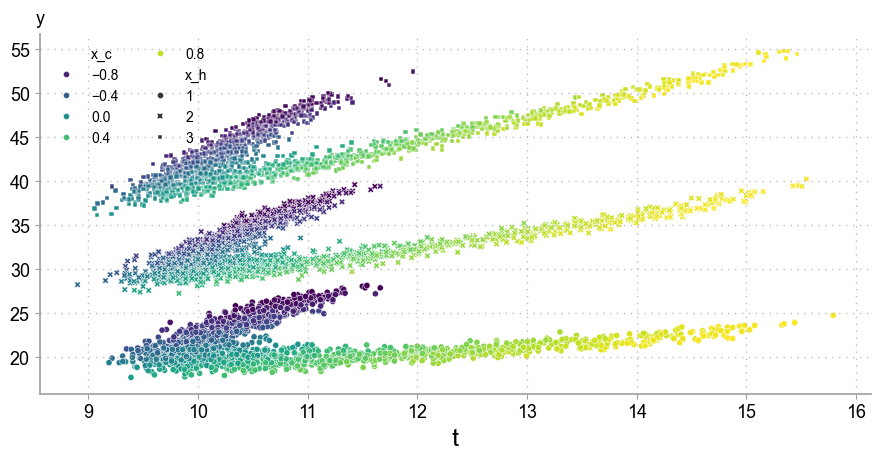

In [26]:
use_plotplainblind()
fig, ax = plt.subplots(figsize=(9, 4.8))
sns.scatterplot(data=df_sim, y="y", x="t", hue="x_c", style="x_h", palette="viridis", ax=ax, s=20)
ax.set_xlabel("t")
ax.set_ylabel("")
set_top_ylabel(ax, "y")
ax.legend(fontsize=10, ncol=2)
plt.tight_layout()
plt.show()

### Residualize Both

- Debias model: $t$ from $x_c$. Denoise model: $y$ from $x_c$ and $x_h$. Boosted trees, 10 fold cross prediction
- Then one regression of residual on residual. The slope lands near the <b style="color:#73000A;">true ATE of 3</b>
- The trees handled the curves in $x_c$, so the final OLS did not have to

```python
debias_m = HistGradientBoostingRegressor(max_depth=3, early_stopping=False, random_state=0)
denoise_m = HistGradientBoostingRegressor(max_depth=3, early_stopping=False, random_state=0)

t_res = cross_val_predict(debias_m, df_sim[["x_c"]], df_sim["t"], cv=10)
y_res = cross_val_predict(denoise_m, df_sim[["x_c", "x_h"]], df_sim["y"], cv=10)

df_res = df_sim.assign(t_res=df_sim["t"] - t_res,
                       y_res=df_sim["y"] - y_res)

smf.ols("y_res ~ t_res", data=df_res).fit().params["t_res"]
```

In [27]:
debias_m = HistGradientBoostingRegressor(max_depth=3, early_stopping=False, random_state=0)
denoise_m = HistGradientBoostingRegressor(max_depth=3, early_stopping=False, random_state=0)

t_res = cross_val_predict(debias_m, df_sim[["x_c"]], df_sim["t"], cv=10)
y_res = cross_val_predict(denoise_m, df_sim[["x_c", "x_h"]], df_sim["y"], cv=10)

df_res = df_sim.assign(t_res=df_sim["t"] - t_res,
                       y_res=df_sim["y"] - y_res)

print("slope of the residual regression:",
      round(float(smf.ols("y_res ~ t_res", data=df_res).fit().params["t_res"]), 3))

slope of the residual regression: 3.055


### Confounding Gone, Heterogeneity Kept

- The same residual cloud twice
- Left, shaded by $x_c$: <b style="color:#73000A;">no pattern</b>. The confounder has nothing left to say
- Right, coloured by $x_h$: <b style="color:#73000A;">three fans, three slopes</b>. The effect heterogeneity is still there
- Residualizing took out what $x_c$ did to $t$ and $y$, and left what $t$ does to $y$

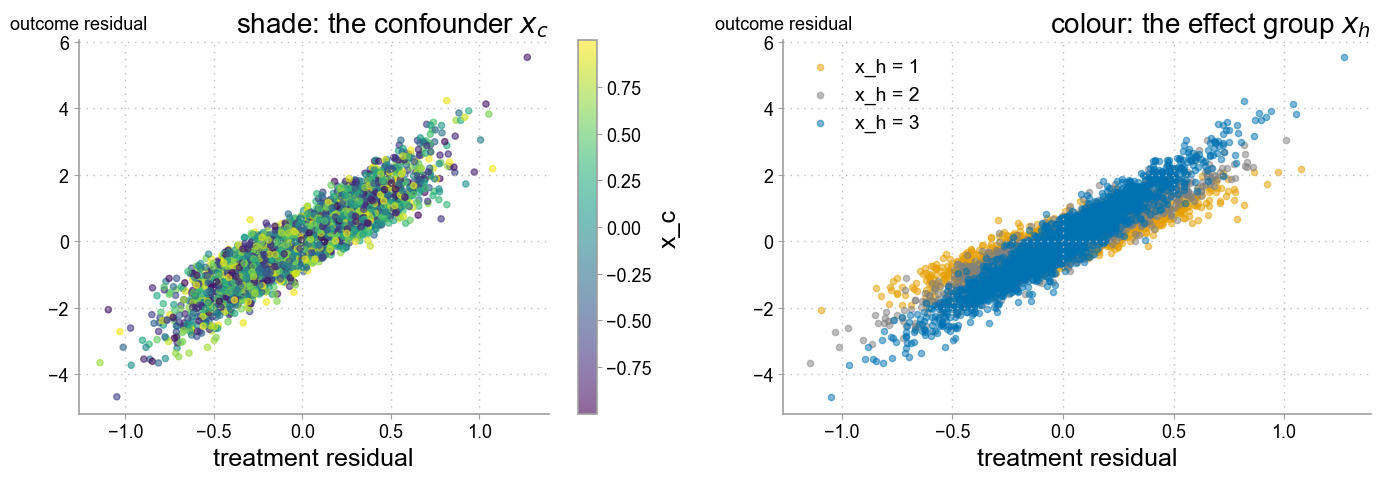

In [28]:
use_plotplainblind()
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

sc = ax1.scatter(df_res["t_res"], df_res["y_res"], c=df_res["x_c"], cmap="viridis", alpha=0.6, s=20)
ax1.set_xlabel("treatment residual")
set_top_ylabel(ax1, "outcome residual")
ax1.set_title("shade: the confounder $x_c$", loc="right")
plt.colorbar(sc, ax=ax1, label="x_c")

colors_h = {1: "#E69F00", 2: "gray", 3: "#0072B2"}
for h in [1, 2, 3]:
    m = df_res["x_h"] == h
    ax2.scatter(df_res[m]["t_res"], df_res[m]["y_res"], color=colors_h[h], alpha=0.5, s=20, label=f"x_h = {h}")
ax2.set_xlabel("treatment residual")
set_top_ylabel(ax2, "outcome residual")
ax2.set_title("colour: the effect group $x_h$", loc="right")
ax2.legend()
plt.tight_layout()
plt.show()

### $Y^*$ Is the Slope Through the Origin

- Both residuals are centred on zero, so each point's own slope from the origin is $\tilde{Y} / \tilde{T}$. That is $Y^*$
- Average $Y^*$ inside an $x_h$ group and you should get that group's CATE: 2, 3 or 4
- One catch: a $\tilde{T}$ near zero makes the division <b style="color:#73000A;">blow up</b>. The weights $\tilde{T}^2$ are the fix. Compare the two averages

```python
df_star = df_res.assign(y_star=df_res["y_res"] / df_res["t_res"],
                        weight=df_res["t_res"] ** 2)
```

In [29]:
df_star = df_res.assign(y_star=df_res["y_res"] / df_res["t_res"],
                        weight=df_res["t_res"] ** 2)

rows = []
for h in [1, 2, 3]:
    g = df_star.query(f"x_h == {h}")
    rows.append(dict(x_h=h, true_cate=1 + h,
                     unweighted_mean=g["y_star"].mean(),
                     weighted_mean=np.average(g["y_star"], weights=g["weight"])))
pd.DataFrame(rows).round(2)

,x_h,true_cate,unweighted_mean,weighted_mean
0,1,2,-1.54,2.02
1,2,3,3.62,2.98
2,3,4,4.46,4.00


### The Weights Mute the Blow-ups

- Point size is the weight $\tilde{T}^2$
- Near the centre $Y^*$ runs off the chart, into the thousands, and those points weigh <b style="color:#73000A;">almost nothing</b>
- Dashed lines: the weighted averages, sitting on 2, 3 and 4

```python
sns.scatterplot(data=df_star, y="y_star", x="t_res", hue="x_h", size="weight")
```

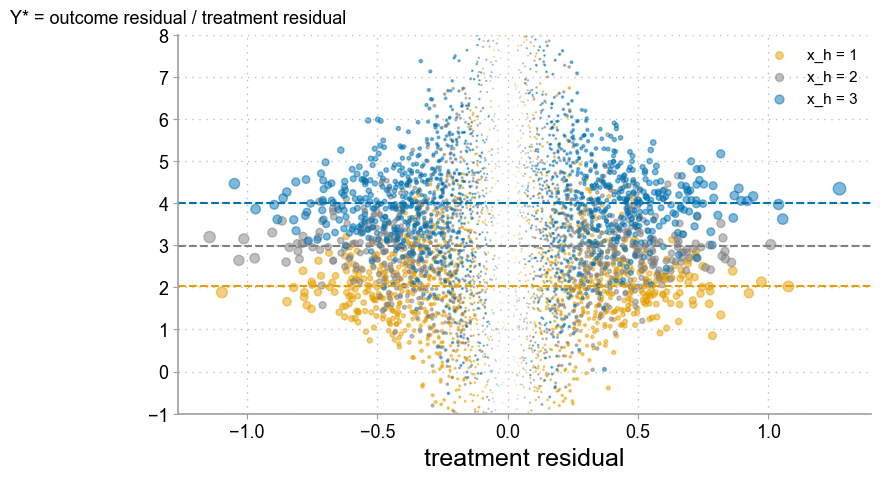

In [30]:
use_plotplainblind()
fig, ax = plt.subplots(figsize=(9, 5))

colors_h = {1: "#E69F00", 2: "gray", 3: "#0072B2"}
for h in [1, 2, 3]:
    g = df_star.query(f"x_h == {h}")
    ax.scatter(g["t_res"], g["y_star"], color=colors_h[h], alpha=0.5, s=g["weight"] * 50, label=f"x_h = {h}")
    ax.axhline(np.average(g["y_star"], weights=g["weight"]), color=colors_h[h], linestyle="--", lw=1.5)

ax.set_xlabel("treatment residual")
set_top_ylabel(ax, "Y* = outcome residual / treatment residual")
ax.set_ylim(-1, 8)
ax.legend(fontsize=11, loc="upper right")
plt.tight_layout()
plt.show()

### Another simple example

- A very simple data generating process: discount affecting sales through a square root

$$
Sales_i = 20 + 10 \sqrt{Discount_i} + e_i
$$

- The treatment effect is the derivative of sales with respect to the treatment

$$
\frac{\partial Sales_i}{\partial Discount_i} = \frac{10}{2\sqrt{Discount_i}}
$$

- <b style="color:#73000A;">Not linear</b>: it gets weaker as the treatment increases
    - A little discount increases sales by a lot; too much discount, and an extra unit affects sales less and less. People won't buy to infinity
- Can the non-parametric ML capture this saturating behavior? Can it extrapolate that a higher discount would have a lower effect? <b style="color:#73000A;">Sort of</b>

### Data From That DGP

```python
np.random.seed(321)
n = 5000
discount = np.random.gamma(2, 10, n).reshape(-1, 1)
discount.sort(axis=0)    # for better plotting
sales = np.random.normal(20 + 10 * np.sqrt(discount), 1)
```

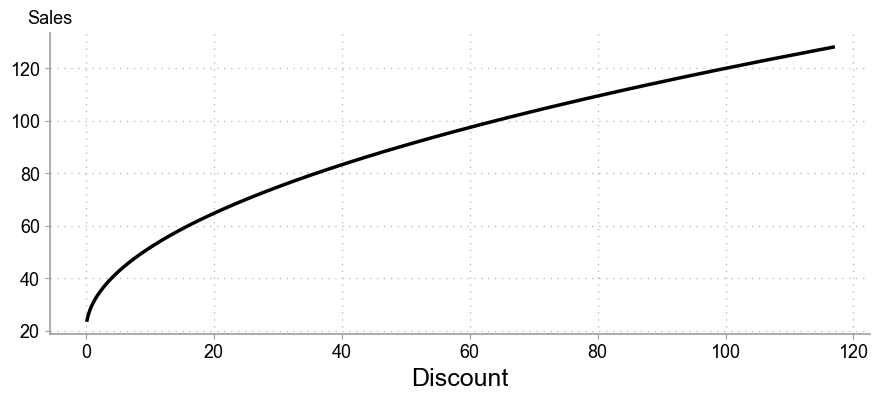

In [31]:
np.random.seed(321)
n = 5000
discount = np.random.gamma(2, 10, n).reshape(-1, 1)
discount.sort(axis=0)    # for better plotting
sales = np.random.normal(20 + 10 * np.sqrt(discount), 1)

use_plotplainblind()
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(discount, 20 + 10 * np.sqrt(discount), lw=2.5)
ax.set_xlabel("Discount")
set_top_ylabel(ax, "Sales")
plt.tight_layout()
plt.show()

### Non-Parametric Double ML on That Data

```python
debias_m = HistGradientBoostingRegressor(max_depth=3, early_stopping=False, random_state=0)
denoise_m = HistGradientBoostingRegressor(max_depth=3, early_stopping=False, random_state=0)

# orthogonalising step
discount_res = discount.ravel() - cross_val_predict(debias_m, np.ones(discount.shape),
                                                    discount.ravel(), cv=5)
sales_res = sales.ravel() - cross_val_predict(denoise_m, np.ones(sales.shape),
                                              sales.ravel(), cv=5)

# final, non parametric causal model
non_param = HistGradientBoostingRegressor(max_depth=3, early_stopping=False, random_state=0)
w = discount_res ** 2
y_star = sales_res / discount_res

non_param.fit(X=discount_res.reshape(-1, 1), y=y_star.ravel(), sample_weight=w.ravel())
```

- No covariates here, so the nuisance models see a column of ones

In [32]:
debias_m = HistGradientBoostingRegressor(max_depth=3, early_stopping=False, random_state=0)
denoise_m = HistGradientBoostingRegressor(max_depth=3, early_stopping=False, random_state=0)

# orthogonalising step
discount_res = discount.ravel() - cross_val_predict(debias_m, np.ones(discount.shape),
                                                    discount.ravel(), cv=5)
sales_res = sales.ravel() - cross_val_predict(denoise_m, np.ones(sales.shape),
                                              sales.ravel(), cv=5)

# final, non parametric causal model
non_param = HistGradientBoostingRegressor(max_depth=3, early_stopping=False, random_state=0)
w = discount_res ** 2
y_star = sales_res / discount_res

non_param.fit(X=discount_res.reshape(-1, 1), y=y_star.ravel(), sample_weight=w.ravel());

### The Underlying Assumption

- The CATE here is not linear: as the treatment increases, the CATE should decrease. Can the non-parametric model capture that?
- Recall what Double/Debiased ML assumes about the data generating process

$$
\tilde{Y}_i = \tau(X_i) \tilde{T}_i + e_i
$$

- The residualized outcome equals the residualized treatment times the conditional treatment effect
- The <b style="color:#73000A;">treatment impacts the outcome linearly</b>. No non-linearity here
    - The outcome rises by a fixed $\tau(X_i)$ whether the treatment goes from 1 to 10 or from 100 to 110. A simple multiplication

### A Locally Linear Approximation

- So the non-parametric model can't capture the non-linearity? Again, not really
- Double-ML <b style="color:#73000A;">finds the locally linear approximation to the non-linear CATE</b>
- The derivative of the outcome with respect to the treatment, at or around that treatment level
- The slopes of the lines tangential to the outcome function at the treatment point

<div style="text-align:center;"><img src="images/facure-dml/linear-aprox.png" width="420"></div>

### The Approximations Against the Truth

- Yes, Non-Parametric Double-ML figures out that the effect is smaller as the treatment increases
- No, it won't find the non-linear treatment effect, but the <b style="color:#73000A;">local linear</b> treatment effect
- The approximations are good

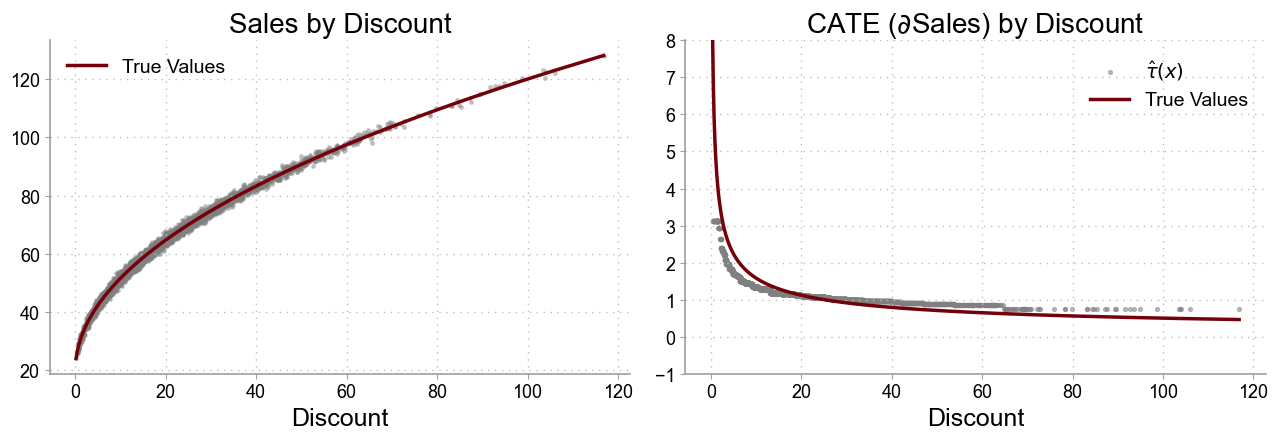

In [33]:
cate = non_param.predict(X=discount)

use_plotplainblind()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
axes[0].scatter(discount, sales, s=6, alpha=.4, color="grey")
axes[0].plot(discount, 20 + 10 * np.sqrt(discount), label="True Values", color="#73000A", lw=2.5)
axes[0].set_title("Sales by Discount")
axes[0].set_xlabel("Discount")
axes[0].legend()

axes[1].scatter(discount, cate, s=8, alpha=.5, color="grey", label=r"$\hat{\tau}(x)$")
axes[1].plot(discount, 5 / np.sqrt(discount), label="True Values", color="#73000A", lw=2.5)
axes[1].set_title(r"CATE ($\partial$Sales) by Discount")
axes[1].set_xlabel("Discount")
axes[1].set_ylim(-1, 8)
axes[1].legend()
plt.tight_layout()
plt.show()

### Very Practical Consequences

- Say you find a treatment effect of 2 for a customer: one more unit of discount, two more units of sales
- "Great! I'll give a lot of discounts to this unit!" The <b style="color:#73000A;">wrong conclusion</b>
- The effect is 2 only <b style="color:#73000A;">at that discount level</b>. Increase the discount, and the effect falls
    - That customer got only 5 in discount, which is why the effect is so high
    - Use it to justify 20 in discount, and the effect might go from 2 to something like 0.5
    - A 20 discount that made sense at an effect of 2 may no longer be profitable at 0.5
- Be extra careful <b style="color:#73000A;">extrapolating a nonlinear treatment effect</b> to a new treatment level
- When the effect is not linear, even non-parametric Double/Debiased-ML struggles to make <b style="color:#73000A;">counterfactual outcome predictions</b>
    - It extrapolates linearly from a low treatment level to a high one, or the other way around. Likely off

## Non-Scientific Double/Debiased ML

- A final idea, much <b style="color:#73000A;">less scientific</b> than everything before: an S-learner after the orthogonalization procedure
- A fundamental shift in mentality: no longer the linear approximation to the CATE. Instead, <b style="color:#73000A;">counterfactual predictions</b>

<div style="text-align:center;"><img src="images/facure-dml/non-sci.png" width="230"></div>

### Slope at a Point, or the Whole Curve

<div style="text-align:center;"><img src="images/facure-dml/cf-pred.png" width="620"></div>

- The CATE is the <b style="color:#73000A;">slope</b> of the outcome function at the data point: how much the outcome changes for a very small increase in the treatment. The derivative
- Counterfactual predictions try to <b style="color:#73000A;">recreate the entire outcome curve</b> from a single data point: the outcome if the treatment were at some other level
- Then we can simulate different treatments for a unit and predict how it would respond
- Very risky business: extrapolating an entire curve from a single point
- Used in practice a lot, never seen in a scientific article showing how or why it works. Simply put: <b style="color:#73000A;">beware!</b>

### One Small Change to the Equation

- So far the residual regression has had a <b style="color:#73000A;">slope</b>

$$
\tilde{Y}_i = \tau(X_i)\,\tilde{T}_i + e_i
$$

- A bigger price surprise moves sales by proportionally more. The effect is a number per day, and it is linear in the treatment
- The change: let the effect depend on the treatment too

$$
\tilde{Y}_i = \tau(X_i, \tilde{T}_i) + e_i
$$

- $\tau$ is now a <b style="color:#73000A;">whole function</b> of the price, not a slope. The first dollar off and the tenth dollar off can do different things

### Learning the Shape from Data

- We do not specify the shape of $\tau(X,\tilde{T})$; we let a flexible ML model learn it.
- Fit a model that predicts residual sales $\tilde{Y}$ using characteristics $X$ and residual price $\tilde{T}$.
- This follows the <b style="color:#73000A;">S-learner recipe</b> with residual sales and residual price instead of their original values.

### The S-Learner Recipe, With the New Variables

- Last lecture: a single model $M_s$ with the <b style="color:#73000A;">treatment as a feature</b>

$$
\mu(x) = E[Y \mid T, X], \qquad \hat{\tau}(x)_i = M_s(X_i, T=1) - M_s(X_i, T=0)
$$

- Same recipe, residuals in place of the raw variables: a single model with the <b style="color:#73000A;">price residual as a feature</b>

$$
\mu(x) = E[\tilde{Y} \mid \tilde{T}, X]
$$

- Price is continuous, so there are no two regimes to compare. Instead, predict with $\tilde{T}$ set to <b style="color:#73000A;">any price we want to try</b>
- The effect of moving from price $p_0$ to price $p_1$ on day $i$: the same subtraction as last lecture

$$
\hat{\tau}_i(p_0 \to p_1) = M_s(X_i, \tilde{T} = p_1 - \hat{M}_t(X_i)) - M_s(X_i, \tilde{T} = p_0 - \hat{M}_t(X_i))
$$

- Recall that $M_t$ is the <b style="color:#73000A;">debias model</b>

### Our Own Cross Prediction Function

- It returns the cross prediction <b style="color:#73000A;">and the models</b> used to make it, since we will need them for $\tilde{T}$

```python
from sklearn.model_selection import KFold

def cv_estimate(train_data, n_splits, model, model_params, X, y):
    cv = KFold(n_splits=n_splits)
    models = []
    cv_pred = pd.Series(np.nan, index=train_data.index)
    for train, test in cv.split(train_data):
        m = model(**model_params)
        m.fit(train_data[X].iloc[train], train_data[y].iloc[train])
        cv_pred.iloc[test] = m.predict(train_data[X].iloc[test])
        models += [m]

    return cv_pred, models
```

In [34]:
def cv_estimate(train_data, n_splits, model, model_params, X, y):
    cv = KFold(n_splits=n_splits)
    models = []
    cv_pred = pd.Series(np.nan, index=train_data.index)
    for train, test in cv.split(train_data):
        m = model(**model_params)
        m.fit(train_data[X].iloc[train], train_data[y].iloc[train])
        cv_pred.iloc[test] = m.predict(train_data[X].iloc[test])
        models += [m]

    return cv_pred, models

### Orthogonalisation, Then the Final Model

```python
params = dict(max_depth=3, early_stopping=False, random_state=0)

y_hat, models_y = cv_estimate(train, 5, HistGradientBoostingRegressor, params, X, y)
t_hat, models_t = cv_estimate(train, 5, HistGradientBoostingRegressor, params, X, T)

y_res = train[y] - y_hat
t_res = train[T] - t_hat

# -1 on price: predictions should not increase as price increases
monotone_constraints = [-1 if col == T else 0 for col in X + [T]]

model_final = HistGradientBoostingRegressor(monotonic_cst=monotone_constraints, **params)
model_final = model_final.fit(X=train[X].assign(price=t_res), y=y_res)
```

- $\tilde{T}$ goes in with $X$, and the model predicts $\tilde{Y}$. Any ML model works
- Boosted trees take <b style="color:#73000A;">monotonic constraints</b>: sales should decrease as price increases, so the model is constrained <b style="color:#73000A;">not to increase</b> its predictions as price increases

In [35]:
params = dict(max_depth=3, early_stopping=False, random_state=0)

y_hat, models_y = cv_estimate(train, 5, HistGradientBoostingRegressor, params, X, y)
t_hat, models_t = cv_estimate(train, 5, HistGradientBoostingRegressor, params, X, T)

y_res = train[y] - y_hat
t_res = train[T] - t_hat

# -1 on price: predictions should not increase as price increases
monotone_constraints = [-1 if col == T else 0 for col in X + [T]]

model_final = HistGradientBoostingRegressor(monotonic_cst=monotone_constraints, **params)
model_final = model_final.fit(X=train[X].assign(price=t_res), y=y_res)

### Simulating Prices

Simulate different price levels for each unit, predict the sales under each
- Step 1: <b style="color:#73000A;">cross join</b> the test set with a price table of all simulated prices

```python
pred_test = (test
             .rename(columns={"price": "factual_price"})
             .assign(jk=1)
             .reset_index()    # create day ID
             .merge(pd.DataFrame(dict(jk=1, price=np.linspace(3, 10, 9))), on="jk")
             .drop(columns=["jk"]))

pred_test.query("index==0")
```

### Nine Simulated Prices For One Day

- Only the day at index 0, a single unit. Its actual, factual price was 7
- Simulated counterfactual treatments from 3 to 10

In [36]:
pred_test = (test
             .rename(columns={"price": "factual_price"})
             .assign(jk=1)
             .reset_index()    # create day ID
             .merge(pd.DataFrame(dict(jk=1, price=np.linspace(3, 10, 9))), on="jk")
             .drop(columns=["jk"]))

pred_test.query("index==0")

,index,temp,weekday,cost,factual_price,sales,price
0,0,25.8,1,0.3,7,230,3.000
1,0,25.8,1,0.3,7,230,3.875
2,0,25.8,1,0.3,7,230,4.750
3,0,25.8,1,0.3,7,230,5.625
4,0,25.8,1,0.3,7,230,6.500
5,0,25.8,1,0.3,7,230,7.375
6,0,25.8,1,0.3,7,230,8.250
7,0,25.8,1,0.3,7,230,9.125
8,0,25.8,1,0.3,7,230,10.000


- Feed those counterfactual prices to the causal model for counterfactual sales predictions
- The model has the format $\widehat{Sales_i} = \hat{\tau}(X_i, \tilde{T}_i)$, so first the price residuals $\tilde{T}_i$
    - Predict with all five treatment models from the cross prediction
    - Average the five predictions into one
    - Subtract the predicted price from the counterfactual price

```python
def ensamble_pred(df, models, X):
    return np.mean([m.predict(df[X]) for m in models], axis=0)

t_res_test = pred_test[T] - ensamble_pred(pred_test, models_t, X)

pred_test["sales_pred"] = model_final.predict(X=pred_test[X].assign(price=t_res_test))
pred_test.query("index==0")
```

In [37]:
def ensamble_pred(df, models, X):
    return np.mean([m.predict(df[X]) for m in models], axis=0)

t_res_test = pred_test[T] - ensamble_pred(pred_test, models_t, X)

pred_test["sales_pred"] = model_final.predict(X=pred_test[X].assign(price=t_res_test))
pred_test.query("index==0")

,index,temp,weekday,cost,factual_price,sales,price,sales_pred
0,0,25.8,1,0.3,7,230,3.000,25.087698
1,0,25.8,1,0.3,7,230,3.875,21.031913
2,0,25.8,1,0.3,7,230,4.750,15.219016
3,0,25.8,1,0.3,7,230,5.625,6.036116
4,0,25.8,1,0.3,7,230,6.500,-1.148155
5,0,25.8,1,0.3,7,230,7.375,-10.696933
6,0,25.8,1,0.3,7,230,8.250,-21.968750
7,0,25.8,1,0.3,7,230,9.125,-25.193383
8,0,25.8,1,0.3,7,230,10.000,-25.193383


### A Sales Prediction for Every Simulated Price

- The lower the price, the higher the sales
- The predictions are <b style="color:#73000A;">off in their level</b>: from about 25 to about -25
    - The model predicts the residualized outcome, which is roughly mean zero
- Fine if all you want is the slope of the sales curve, the price treatment effect
- To fix the levels, add the predictions from the denoising model $M_y$

```python
y_hat_test = ensamble_pred(pred_test, models_y, X)
pred_test["sales_pred"] = (y_hat_test +
                           model_final.predict(X=pred_test[X].assign(price=t_res_test)))
pred_test.query("index==0")
```

In [38]:
y_hat_test = ensamble_pred(pred_test, models_y, X)
pred_test["sales_pred"] = (y_hat_test +
                           model_final.predict(X=pred_test[X].assign(price=t_res_test)))
pred_test.query("index==0")

,index,temp,weekday,cost,factual_price,sales,price,sales_pred
0,0,25.8,1,0.3,7,230,3.000,255.290918
1,0,25.8,1,0.3,7,230,3.875,251.235133
2,0,25.8,1,0.3,7,230,4.750,245.422236
3,0,25.8,1,0.3,7,230,5.625,236.239336
4,0,25.8,1,0.3,7,230,6.500,229.055064
5,0,25.8,1,0.3,7,230,7.375,219.506287
6,0,25.8,1,0.3,7,230,8.250,208.234470
7,0,25.8,1,0.3,7,230,9.125,205.009837
8,0,25.8,1,0.3,7,230,10.000,205.009837


In [39]:
# Compact version of the non-scientific cells above, same result
y_hat, models_y = cv_estimate(train, 5, HistGradientBoostingRegressor, params, X, y)
t_hat, models_t = cv_estimate(train, 5, HistGradientBoostingRegressor, params, X, T)
model_final = HistGradientBoostingRegressor(monotonic_cst=monotone_constraints, **params)
model_final.fit(train[X].assign(price=train[T] - t_hat), train[y] - y_hat)
grid = test.rename(columns={"price": "factual_price"}).assign(jk=1).reset_index().merge(
    pd.DataFrame(dict(jk=1, price=np.linspace(3, 10, 9))), on="jk").drop(columns=["jk"])
grid["sales_pred"] = (ensamble_pred(grid, models_y, X) +
                      model_final.predict(grid[X].assign(price=grid[T] - ensamble_pred(grid, models_t, X))))

### Unit Level Sales Curves

- Ten sampled units, and how they would behave under different prices

```python
np.random.seed(1)
sample_ids = np.random.choice(pred_test["index"].unique(), 10)

sns.lineplot(data=pred_test.query("index in @sample_ids"),
             x="price", y="sales_pred", hue="index")
```

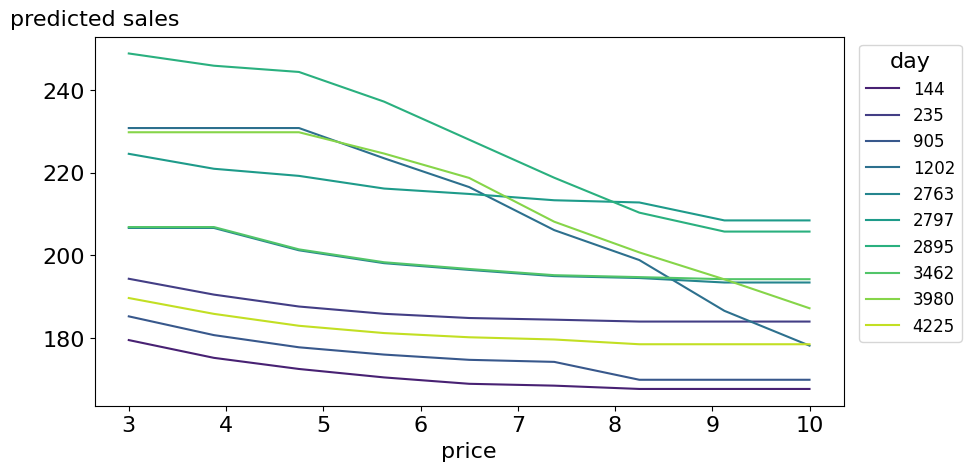

In [40]:
np.random.seed(1)
sample_ids = np.random.choice(pred_test["index"].unique(), 10)

plt.style.use("default")
matplotlib.rcParams.update({'font.size': 16})
fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(data=pred_test.query("index in @sample_ids").assign(day=lambda d: d["index"].astype(str)),
             x="price", y="sales_pred", hue="day", palette="viridis", ax=ax)
ax.set_xlabel("price")
ax.set_ylabel("")
set_top_ylabel(ax, "predicted sales")
ax.legend(title="day", loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=12)
plt.tight_layout()
plt.show()

### Same Starting Point

- Some units are <b style="color:#73000A;">very sensitive</b> to price: sales drop from about 250 to almost 200 as the price goes from 3 to 10
- Others are <b style="color:#73000A;">very inelastic</b>: from about 195 to about 185 over the same prices
- Hard to see these differences, so make all the curves start from the same point, the average sales
- Some units have a sharp drop in sales as prices rise, others not so much

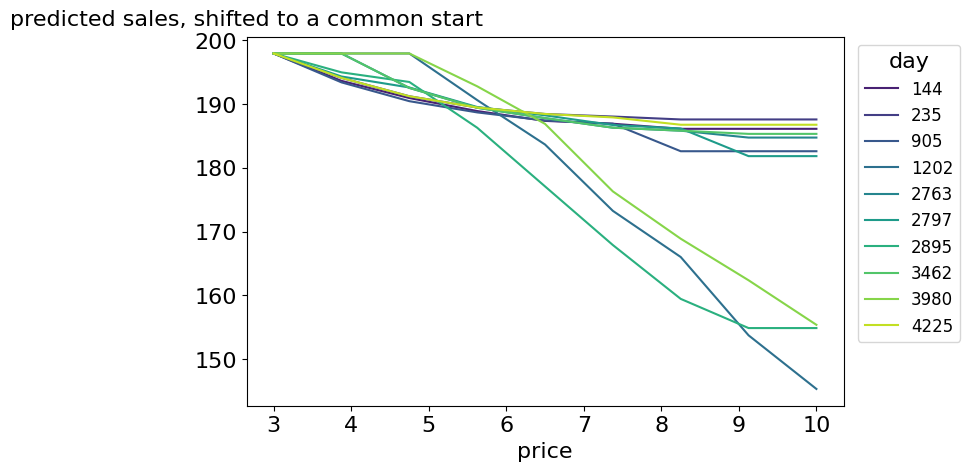

In [41]:
shifted = (pred_test
           .query("index in @sample_ids")
           .assign(max_sales=lambda d: d.groupby("index")[["sales_pred"]].transform("max"))
           .assign(sales_pred=lambda d: d["sales_pred"] - d["max_sales"] + d["sales_pred"].mean()))

plt.style.use("default")
matplotlib.rcParams.update({'font.size': 16})
fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(data=shifted.assign(day=lambda d: d["index"].astype(str)),
             x="price", y="sales_pred", hue="day", palette="viridis", ax=ax)
ax.set_xlabel("price")
ax.set_ylabel("")
set_top_ylabel(ax, "predicted sales, shifted to a common start")
ax.legend(title="day", loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=12)
plt.tight_layout()
plt.show()

### More Econometrics May Be Needed!

<div style="text-align:center;"><img src="images/facure-dml/more-metrics.png" width="150"></div>

- A word of caution. Not called non-scientific for nothing: a <b style="color:#73000A;">hack</b> to get non linear counterfactual predictions, with downsides
- First and foremost, the problem all ML techniques have when applied naively to causal inference: <b style="color:#73000A;">bias</b>
    - The final model is a regularized ML model, and that regularization can bias the causal estimate to zero
- Second, the ML algorithm you choose. Here, boosted trees
    - Trees are not very good at <b style="color:#73000A;">smooth</b> predictions: discontinuities, a stepwise behavior here and there in the plots above
    - Trees are not very good at <b style="color:#73000A;">extrapolating</b>: weird predictions for prices never seen before

### Prices Never Seen Before

- The same curves, with simulated prices from 3 to 30. The data stop around 10

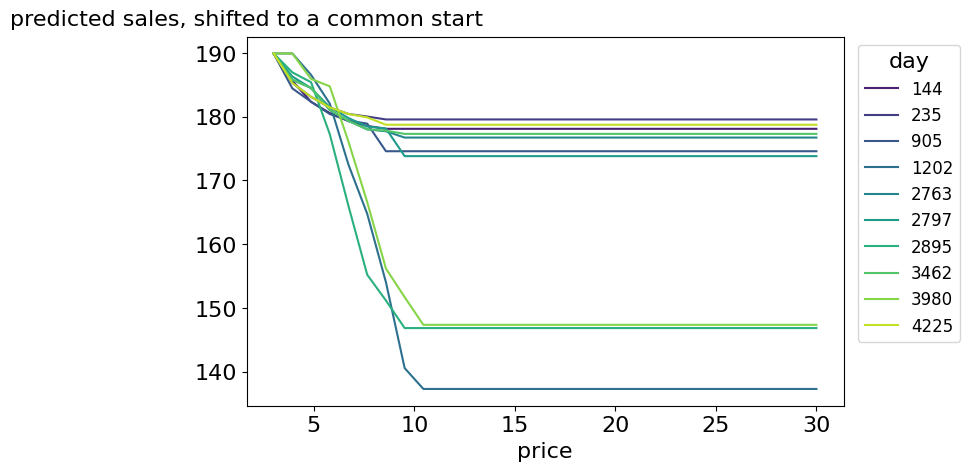

In [42]:
pred_test = (test
             .rename(columns={"price": "factual_price"})
             .assign(jk=1)
             .reset_index()    # create day ID
             .merge(pd.DataFrame(dict(jk=1, price=np.linspace(3, 30, 30))), on="jk")
             .drop(columns=["jk"]))

t_res_test = pred_test[T] - ensamble_pred(pred_test, models_t, X)
y_hat_test = ensamble_pred(pred_test, models_y, X)
pred_test["sales_pred"] = model_final.predict(X=pred_test[X].assign(price=t_res_test)) + y_hat_test

shifted = (pred_test
           .query("index in @sample_ids")
           .assign(max_sales=lambda d: d.groupby("index")[["sales_pred"]].transform("max"))
           .assign(sales_pred=lambda d: d["sales_pred"] - d["max_sales"] + d["sales_pred"].mean()))

plt.style.use("default")
matplotlib.rcParams.update({'font.size': 16})
fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(data=shifted.assign(day=lambda d: d["index"].astype(str)),
             x="price", y="sales_pred", hue="day", palette="viridis", ax=ax)
ax.set_xlabel("price")
ax.set_ylabel("")
set_top_ylabel(ax, "predicted sales, shifted to a common start")
ax.legend(title="day", loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=12)
plt.tight_layout()
plt.show()

### Highly Dependent on the Final ML Model

- Regularize it too much, and the causal estimates are <b style="color:#73000A;">biased to zero</b>
- Use this or that ML algorithm, and its limitations carry into the counterfactual predictions
- Worth a try? By all means, give it a shot. Just don't forget the downsides

### The Whole Procedure in a Diagram

<div style="text-align:center;"><img src="images/facure-dml/diagram.png" width="700"></div>

### Sources

- Matheus Facure, <b style="color:#73000A;">Causal Inference for the Brave and True</b>, chapter 22, Debiased/Orthogonal Machine Learning: the text, the images, the data, in his order
- Chernozhukov et al (2016), *Double/Debiased Machine Learning for Treatment and Causal Parameters*
- Foster and Syrgkanis (2019), *Orthogonal Statistical Learning*; the *econml* library documentation
- Nie and Wager (2020) on the R-loss; Athey et al (2019) on causal decision trees; the later Chernozhukov papers
- One image from Pedro Sant'Anna's slides
- Gradient boosting here is scikit-learn's `HistGradientBoostingRegressor` in place of LightGBM, and the gain curves are normalized

## Key Ideas

- Double/Debiased/Orthogonal ML <b style="color:#73000A;">delegates the nuisance parameters</b>, so all attention goes to the causal parameter. A two step orthogonalisation
    1. Fit $M_t(X)$ to predict the treatment from the covariates; out of fold residuals $\tilde{t} = t - M_t(X)$. The <b style="color:#73000A;">debiasing</b> model: the residuals are, by definition, orthogonal to the features that built them
    2. Fit $M_y(X)$ to predict the outcome from the covariates; out of fold residuals $\tilde{y} = y - M_y(X)$. The <b style="color:#73000A;">denoising</b> model: a version of the outcome with all the variance from the features explained away
- Provided there are no unmeasured confounders, regress $\tilde{y}$ on $\tilde{t}$ for a linear approximation to the ATE
- Interact $\tilde{t}$ with the covariates for the CATE, or use the <b style="color:#73000A;">weighting trick</b> to allow any generic ML model as the final CATE model
- Orthogonalization is a general tool for causal learning: feed the residuals to an S-learner style algorithm and get counterfactual predictions from simulated treatments. A pre-processing step in many causal inference applications